In [3]:
import numpy as np
from scipy import stats

def calculate_win_probabilities_t(horse_data, std_dev=4, degrees_of_freedom=5, num_simulations=100000):
    """
    Calculate winning probabilities for horses using Student's t-distribution.
    
    Parameters:
    -----------
    horse_data : dict or list
        If dict: {horse_number: mean_length} mapping
        If list: Just the mean lengths (horse numbers will be 1 to len(list))
    std_dev : float
        Standard deviation for all horses
    degrees_of_freedom : float
        Degrees of freedom for t-distribution (lower = fatter tails)
    num_simulations : int
        Number of race simulations to run
        
    Returns:
    --------
    dict
        Dictionary with horse numbers as keys and win probabilities as values
    """
    # Convert input to a dictionary if it's a list
    if isinstance(horse_data, list):
        horse_data = {i+1: mean for i, mean in enumerate(horse_data)}
    
    # Extract horse numbers and means
    horse_numbers = list(horse_data.keys())
    horse_means = np.array(list(horse_data.values()))
    
    num_horses = len(horse_numbers)
    win_counts = np.zeros(num_horses)
    
    # Create a t-distribution with specified degrees of freedom
    t_dist = stats.t(df=degrees_of_freedom)
    
    # Run simulations
    for _ in range(num_simulations):
        # Generate random finishes for all horses
        random_effects = t_dist.rvs(size=num_horses) * std_dev
        finishes = horse_means + random_effects
        
        # Find winner (horse with highest finish value)
        winner_idx = np.argmax(finishes)
        win_counts[winner_idx] += 1
    
    # Convert counts to probabilities
    win_probabilities = win_counts / num_simulations
    
    # Return as dictionary mapping horse number to probability
    return {horse_num: prob for horse_num, prob in zip(horse_numbers, win_probabilities)}





In [ ]:
# import pandas as pd
# p = 'C://Users/Blake/Code/Sports/horse_cap_tracker/data/ai_picks/2026-04-16/keeneland/gemini.csv'
# test = pd.read_csv(p)
# test = test.drop(columns=['gemini_closing_prob'])
# test.to_csv(p, index=False)

In [4]:
def print_win_probabilities(horse_means, probabilities):
    """
    Print formatted win probabilities.
    """
    print("\nHorse Win Probabilities:")
    print("-----------------------")
    for i, mean in enumerate(horse_means):
        print(f"Horse {i+1} (mean: {mean:+.1f}): {probabilities[i]:.2%}")
    print()

In [5]:
def convert_to_racing_odds(probabilities):
    """
    Convert winning probabilities to different odds formats used in horse racing.
    
    Parameters:
    -----------
    probabilities : dict
        Dictionary with horse numbers as keys and win probabilities as values
    
    Returns:
    --------
    dict
        Dictionary with horse numbers as keys and a tuple of 
        (probability, american_odds, fractional_odds) as values
    """
    results = {}
    
    for horse_num, prob in probabilities.items():
        # Calculate American odds
        if prob >= 0.5:  # Favorite
            american_odds = -100 / (prob - 1)
        else:  # Underdog
            american_odds = 100 / prob - 100
        
        # Round American odds to nearest 5 or 10 as typically done in betting
        american_odds = round(american_odds / 5) * 5
        
        # Calculate fractional odds (traditional horse racing display)
        if prob >= 0.5:  # Odds-on (favorite)
            numerator = 1
            denominator = round(1 / prob - 1, 2)
            # Round to common fractions for readability
            if 0.32 <= denominator <= 0.34:  # Close to 1/3
                denominator = 1/3
            elif 0.24 <= denominator <= 0.26:  # Close to 1/4
                denominator = 1/4
            elif 0.19 <= denominator <= 0.21:  # Close to 1/5
                denominator = 1/5
            fractional = f"1-{denominator:.2g}"
        else:  # Odds-against (underdog)
            numerator = round((1 - prob) / prob, 2)
            # Round to common whole numbers
            if numerator < 10:
                numerator = round(numerator)
            else:
                numerator = round(numerator / 5) * 5
            fractional = f"{numerator}-1"
        
        # Create tuple with all odds formats
        results[horse_num] = (prob, american_odds, fractional)
    
    return results



In [6]:
def display_horse_odds(horse_data, probabilities=None):
    """
    Display formatted odds table for horses.
    
    Parameters:
    -----------
    horse_data : dict or list
        If dict: {horse_number: mean_length} mapping
        If list: Just the mean lengths (horse numbers will be 1 to len(list))
    probabilities : dict, optional
        Dictionary with horse numbers and win probabilities
        If None, will be calculated using Student's t with dof=5
    """
    # Convert input to a dictionary if it's a list
    if isinstance(horse_data, list):
        horse_data = {i+1: mean for i, mean in enumerate(horse_data)}
    
    # Calculate probabilities if not provided
    if probabilities is None:
        probabilities = calculate_win_probabilities_t(horse_data)
    
    odds_data = convert_to_racing_odds(probabilities)
    
    print("\nHorse Racing Odds Board")
    print("======================")
    print(f"{'#':<4} {'Mean':<8} {'Win %':<10} {'US Odds':<10} {'Fractional':<10}")
    print("-" * 50)
    
    # Sort by probability (descending)
    sorted_horses = sorted(odds_data.items(), key=lambda x: x[1][0], reverse=True)
    
    for horse_num, (prob, american, fractional) in sorted_horses:
        mean = horse_data[horse_num]
        
        # Format American odds with +/- sign
        if american > 0:
            american_str = f"+{american}"
        else:
            american_str = f"{american}"
            
        print(f"{horse_num:<4} {mean:+.1f}{'':<6} {prob:.1%}{'':<5} {american_str:<10} {fractional:<10}")
    print()

In [7]:
# Example usag
# Example projected lengths (positive = ahead of median)
horse_data = {1: 7.25, 2: 6.25, 3: -3.75, 4: -4.25, 5: -11.75, 6: -10.75, 7: 1.25}

# Calculate with default parameters (dof=5)
probs = calculate_win_probabilities_t(horse_data)
# print_win_probabilities(horse_means, probs)

# Try with different degrees of freedom
for dof in [1.3]:
    print(f"Using t-distribution with {dof} degrees of freedom:")
    r1_probs = calculate_win_probabilities_t(horse_data, degrees_of_freedom=dof)
    # print_win_probabilities(horse_means, probs)
    display_horse_odds(horse_data, r1_probs)

Using t-distribution with 1.3 degrees of freedom:

Horse Racing Odds Board
#    Mean     Win %      US Odds    Fractional
--------------------------------------------------
1    +7.2       37.7%      +165       2-1       
2    +6.2       31.2%      +220       2-1       
7    +1.2       12.1%      +725       7-1       
3    -3.8       6.1%      +1530      15-1      
4    -4.2       6.0%      +1580      15-1      
6    -10.8       3.5%      +2760      30-1      
5    -11.8       3.4%      +2845      30-1      



In [8]:
# Example usag
# Example projected lengths (positive = ahead of median)
horse_data = {
    3:-3,
    4:1,
    5:0,
    7:3,
    8:-10,
    9:-10,
    10:-7,
    12:-13,
    14:-7
}

# Calculate with default parameters (dof=5)
probs = calculate_win_probabilities_t(horse_data)
# print_win_probabilities(horse_means, probs)

# Try with different degrees of freedom
for dof in [1.3]:
    print(f"Using t-distribution with {dof} degrees of freedom:")
    r2_probs = calculate_win_probabilities_t(horse_data, degrees_of_freedom=dof)
    # print_win_probabilities(horse_means, probs)
    display_horse_odds(horse_data, r2_probs)

Using t-distribution with 1.3 degrees of freedom:

Horse Racing Odds Board
#    Mean     Win %      US Odds    Fractional
--------------------------------------------------
7    +3.0       29.8%      +235       2-1       
4    +1.0       19.8%      +405       4-1       
5    +0.0       16.6%      +505       5-1       
3    -3.0       9.7%      +925       9-1       
14   -7.0       5.8%      +1620      15-1      
10   -7.0       5.8%      +1640      15-1      
9    -10.0       4.6%      +2090      20-1      
8    -10.0       4.4%      +2195      20-1      
12   -13.0       3.6%      +2640      25-1      



In [9]:

# Example usag
# Example projected lengths (positive = ahead of median)
horse_data = {
    1:1.13,
    3:-0.88,
    4:2.63,
    5:-3.88,
    6:-16.88,
    7:-0.38,
    8:-5.88,
    9:-17.88
}

# Calculate with default parameters (dof=5)
r3_probs = calculate_win_probabilities_t(horse_data)
# print_win_probabilities(horse_means, probs)

# Try with different degrees of freedom
for dof in [1.3]:
    print(f"Using t-distribution with {dof} degrees of freedom:")
    r3_probs = calculate_win_probabilities_t(horse_data, degrees_of_freedom=dof)
    # print_win_probabilities(horse_means, probs)
    display_horse_odds(horse_data, r3_probs)


Using t-distribution with 1.3 degrees of freedom:

Horse Racing Odds Board
#    Mean     Win %      US Odds    Fractional
--------------------------------------------------
4    +2.6       28.2%      +255       3-1       
1    +1.1       21.0%      +375       4-1       
7    -0.4       15.6%      +540       5-1       
3    -0.9       14.2%      +605       6-1       
5    -3.9       8.6%      +1070      10-1      
8    -5.9       6.7%      +1385      15-1      
9    -17.9       2.9%      +3380      35-1      
6    -16.9       2.8%      +3420      35-1      



In [10]:


# Example usag
# Example projected lengths (positive = ahead of median)
horse_data = {
    1:0,
    2:-6,
    3:0,
    4:-8,
    5:-1,
    6:-6.5,
    8:3,
    9:1,
    10:-6,
    11:-1,
    12:4.5,
    13:-12.5,
    14:-29
}

# Calculate with default parameters (dof=5)
# probs = calculate_win_probabilities_t(horse_data)
# print_win_probabilities(horse_means, probs)

# Try with different degrees of freedom
for dof in [1.3]:
    print(f"Using t-distribution with {dof} degrees of freedom:")
    r4_probs = calculate_win_probabilities_t(horse_data, degrees_of_freedom=dof)
    # print_win_probabilities(horse_means, probs)
    display_horse_odds(horse_data, r4_probs)



Using t-distribution with 1.3 degrees of freedom:

Horse Racing Odds Board
#    Mean     Win %      US Odds    Fractional
--------------------------------------------------
12   +4.5       20.1%      +400       4-1       
8    +3.0       14.9%      +575       6-1       
9    +1.0       10.5%      +855       9-1       
1    +0.0       8.9%      +1025      10-1      
3    +0.0       8.9%      +1030      10-1      
5    -1.0       7.7%      +1195      10-1      
11   -1.0       7.7%      +1200      10-1      
10   -6.0       4.5%      +2110      20-1      
2    -6.0       4.5%      +2125      20-1      
6    -6.5       4.3%      +2210      20-1      
4    -8.0       3.8%      +2555      25-1      
13   -12.5       2.9%      +3370      35-1      
14   -29.0       1.5%      +6770      70-1      



In [11]:
# Example usag
# Example projected lengths (positive = ahead of median)
horse_data = {
    1:-13.5,
    2:-13.5,
    3:-14.5,
    4:-26,
    6:-13.5,
    7:2.5,
    8:-20.5,
    9:0,
    10:12.5,
}

# Calculate with default parameters (dof=5)
# probs = calculate_win_probabilities_t(horse_data)
# print_win_probabilities(horse_means, probs)

# Try with different degrees of freedom
for dof in [1.3]:
    print(f"Using t-distribution with {dof} degrees of freedom:")
    r5_probs = calculate_win_probabilities_t(horse_data, degrees_of_freedom=dof)
    # print_win_probabilities(horse_means, probs)
    display_horse_odds(horse_data, r5_probs)


Using t-distribution with 1.3 degrees of freedom:

Horse Racing Odds Board
#    Mean     Win %      US Odds    Fractional
--------------------------------------------------
10   +12.5       64.4%      +280       1-0.55    
7    +2.5       12.6%      +695       7-1       
9    +0.0       8.7%      +1045      10-1      
1    -13.5       2.8%      +3495      35-1      
6    -13.5       2.7%      +3560      35-1      
2    -13.5       2.7%      +3625      35-1      
3    -14.5       2.6%      +3775      40-1      
8    -20.5       1.9%      +5140      50-1      
4    -26.0       1.6%      +6210      60-1      




Top Pick 5 Ticket Options:

Option 1: Cost $1.00, Win Probability: 0.41%
--------------------------------------------------
Race 1: 1
Race 2: 7
Race 3: 4
Race 4: 12
Race 5: 10
Expected value (for $1000 payout): $3.10

Option 2: Cost $60.00, Win Probability: 9.12%
--------------------------------------------------
Race 1: 1, 2
Race 2: 7, 4, 5
Race 3: 4, 1
Race 4: 12, 8, 9, 1, 3
Race 5: 10
Expected value (for $1000 payout): $31.17

Option 3: Cost $240.00, Win Probability: 21.34%
--------------------------------------------------
Race 1: 1, 2
Race 2: 7, 4, 5
Race 3: 4, 1, 7, 3, 5
Race 4: 12, 8, 9, 1, 3, 5, 11, 10
Race 5: 10
Expected value (for $1000 payout): $-26.58

Option 4: Cost $440.00, Win Probability: 28.19%
--------------------------------------------------
Race 1: 1, 2
Race 2: 7, 4, 5, 3
Race 3: 4, 1, 7, 3, 5
Race 4: 12, 8, 9, 1, 3, 5, 11, 10, 2, 6, 4
Race 5: 10
Expected value (for $1000 payout): $-158.06

Option 5: Cost $1080.00, Win Probability: 39.61%
-------------------------

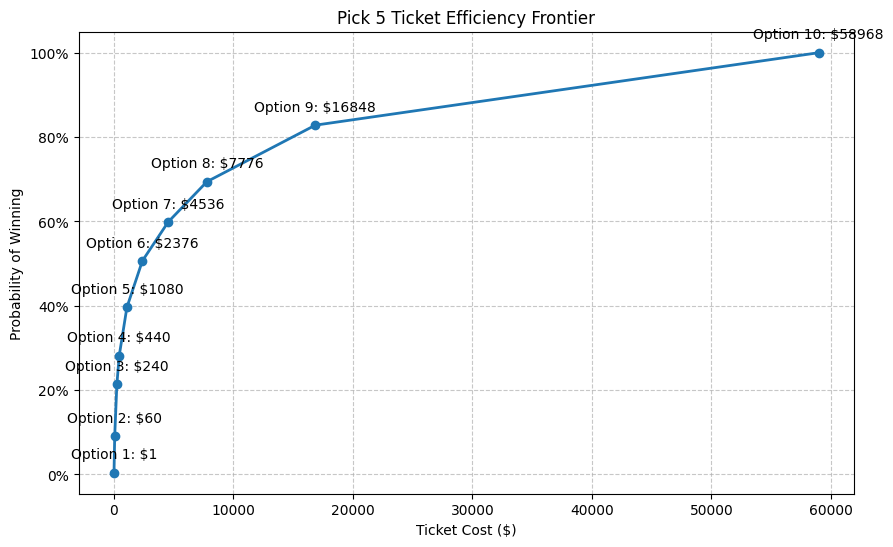

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import itertools
from operator import itemgetter

def optimize_pick5_tickets(race_probs, max_cost=None, min_prob=None, budget_steps=20):
    """
    Optimize Pick 5 tickets to maximize probability while minimizing cost.
    
    Parameters:
    -----------
    race_probs : dict of dicts
        Dictionary of race probabilities, e.g. {
            'r1_probs': {1: 0.4, 2: 0.3, 6: 0.1, ...},
            'r2_probs': {3: 0.5, 4: 0.2, ...},
            ...
        }
    max_cost : int, optional
        Maximum number of combinations to consider
    min_prob : float, optional
        Minimum total probability to aim for
    budget_steps : int
        Number of points on the efficiency frontier to calculate
        
    Returns:
    --------
    list of tuples
        Each tuple contains (cost, probability, ticket_selections)
        where ticket_selections is a dict mapping race name to list of horse numbers
    """
    # Extract race names and probabilities
    races = list(race_probs.keys())
    if len(races) != 5:
        raise ValueError("This function requires exactly 5 races")
    
    # For each race, sort horses by probability (descending)
    sorted_horses = {}
    for race, probs in race_probs.items():
        sorted_horses[race] = sorted(probs.items(), key=itemgetter(1), reverse=True)
    
    # Calculate total cost and probability for selecting top N horses in each race
    solutions = []
    
    # Generate all reasonable combinations of horse counts per race
    # This is more efficient than trying every possible combination
    max_horses_per_race = [len(sorted_horses[race]) for race in races]
    
    # Start with the most probable horse in each race
    min_selection = [1, 1, 1, 1, 1]
    
    # Try different allocations of horses
    all_allocations = []
    
    # Generate allocations from minimum to maximum
    for total_horses in range(sum(min_selection), sum(max_horses_per_race) + 1):
        # Only consider allocations where we have at least 1 horse per race
        # This uses stars and bars method to distribute horses
        for allocation in itertools.combinations_with_replacement(range(5), total_horses - 5):
            counts = [1, 1, 1, 1, 1]  # Start with minimum 1 horse per race
            for i in allocation:
                counts[i] += 1
                
            # Skip if any race exceeds its maximum
            if any(counts[i] > max_horses_per_race[i] for i in range(5)):
                continue
                
            all_allocations.append(counts)
    
    # Calculate cost and probability for each allocation
    results = []
    for allocation in all_allocations:
        # Calculate ticket cost (number of combinations)
        cost = np.prod(allocation)
        
        # Skip if cost exceeds max_cost
        if max_cost is not None and cost > max_cost:
            continue
            
        # Calculate total probability
        total_prob = 1.0
        selections = {}
        
        for i, race in enumerate(races):
            race_prob = 0
            # Get top N horses for this race
            top_horses = sorted_horses[race][:allocation[i]]
            # Sum their probabilities
            race_prob = sum(prob for _, prob in top_horses)
            # Multiply by other races' probabilities
            total_prob *= race_prob
            
            # Store the selected horse numbers
            selections[race] = [horse_num for horse_num, _ in top_horses]
        
        # Skip if probability is below minimum
        if min_prob is not None and total_prob < min_prob:
            continue
            
        results.append((cost, total_prob, selections))
    
    # Sort by efficiency (probability per unit cost)
    results.sort(key=lambda x: x[1]/x[0], reverse=True)
    
    # Find the Pareto frontier (points where no other point has both better cost and better probability)
    frontier = []
    best_prob = 0
    
    # Sort by cost
    sorted_by_cost = sorted(results, key=itemgetter(0))
    
    for result in sorted_by_cost:
        cost, prob, selections = result
        if prob > best_prob:
            frontier.append(result)
            best_prob = prob
    
    # If budget_steps is provided, return evenly spaced points along the frontier
    if frontier and budget_steps > 0:
        if budget_steps >= len(frontier):
            return frontier
        
        # Get evenly spaced indices
        indices = np.linspace(0, len(frontier)-1, budget_steps, dtype=int)
        return [frontier[i] for i in indices]
    
    return frontier


def plot_pick5_frontier(frontier):
    """
    Plot the efficiency frontier for Pick 5 tickets.
    
    Parameters:
    -----------
    frontier : list of tuples
        List of (cost, probability, selections) tuples
    """
    costs = [item[0] for item in frontier]
    probs = [item[1] for item in frontier]
    
    plt.figure(figsize=(10, 6))
    plt.plot(costs, probs, 'o-', linewidth=2)
    
    # Add labels for each point
    for i, (cost, prob, _) in enumerate(frontier):
        plt.annotate(f"Option {i+1}: ${cost}",
                    (cost, prob),
                    textcoords="offset points",
                    xytext=(0, 10),
                    ha='center')
    
    plt.xlabel('Ticket Cost ($)')
    plt.ylabel('Probability of Winning')
    plt.title('Pick 5 Ticket Efficiency Frontier')
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # Format y-axis as percentage
    plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    
    return plt


def print_pick5_ticket_options(frontier, top_n=5):
    """
    Print the top N ticket options from the frontier.
    
    Parameters:
    -----------
    frontier : list of tuples
        List of (cost, probability, selections) tuples
    top_n : int
        Number of options to print
    """
    print("\nTop Pick 5 Ticket Options:")
    print("==========================")
    
    for i, (cost, prob, selections) in enumerate(frontier[:min(top_n, len(frontier))]):
        print(f"\nOption {i+1}: Cost ${cost:.2f}, Win Probability: {prob:.2%}")
        print("-" * 50)
        
        for race, horses in selections.items():
            print(f"{race}: {', '.join(map(str, horses))}")
        
        expected_value = prob * 1000 - cost  # Assuming $1000 payout
        print(f"Expected value (for $1000 payout): ${expected_value:.2f}")


# Example usage
if __name__ == "__main__":
    
    race_probs = {
        'Race 1': r1_probs,
        'Race 2': r2_probs,
        'Race 3': r3_probs,
        'Race 4': r4_probs,
        'Race 5': r5_probs
    }
    
    # Find optimal tickets with different budget constraints
    frontier = optimize_pick5_tickets(race_probs, budget_steps=10)
    
    # Print top options
    print_pick5_ticket_options(frontier)
    
    # Plot the efficiency frontier
    plot = plot_pick5_frontier(frontier)
    plot.show()

In [13]:
def optimize_pick5_tickets(race_probs, morning_lines=None, pool_size=100000, takeout_rate=0.22, max_cost=None, min_prob=None, budget_steps=20):
    """
    Optimize Pick 5 tickets to maximize expected value using both
    estimated true probabilities and morning line odds.
    
    Parameters:
    -----------
    race_probs : dict of dicts
        Dictionary of race probabilities, e.g. {
            'Race 1': {1: 0.4, 2: 0.3, 6: 0.1, ...},
            'Race 2': {3: 0.5, 4: 0.2, ...},
            ...
        }
    morning_lines : dict of dicts, optional
        Dictionary of morning line odds in fractional format, e.g. {
            'Race 1': {1: "2-1", 2: "5-2", 6: "8-1", ...},
            'Race 2': {3: "6-5", 4: "3-1", ...},
            ...
        }
    pool_size : float
        Estimated total amount in the Pick 5 pool
    takeout_rate : float
        Track's takeout percentage (0.22 = 22%)
    max_cost : int, optional
        Maximum number of combinations to consider
    min_prob : float, optional
        Minimum total probability to aim for
    budget_steps : int
        Number of points on the efficiency frontier to calculate
        
    Returns:
    --------
    list of tuples
        Each tuple contains (cost, ev, probability, ticket_selections)
        where ticket_selections is a dict mapping race to list of horse numbers
    """
    # Extract race names and probabilities
    races = list(race_probs.keys())
    if len(races) != 5:
        raise ValueError("This function requires exactly 5 races")
    
    # Convert morning line odds to implied probabilities if provided
    market_probs = {}
    if morning_lines:
        for race, odds_dict in morning_lines.items():
            market_probs[race] = {}
            for horse, odds_str in odds_dict.items():
                # Parse fractional odds (e.g., "2-1" or "1-2")
                if "-" in odds_str:
                    num, denom = odds_str.split("-")
                    num, denom = float(num), float(denom)
                    # Convert to implied probability
                    if num >= denom:  # e.g., 2-1
                        prob = denom / (num + denom)
                    else:  # e.g., 1-2
                        prob = denom / (num + denom)
                    market_probs[race][horse] = prob
    
    # Calculate the "true" probabilities of each combination winning
    # based on our t-distribution model
    
    # For each race, sort horses by probability (descending)
    sorted_horses = {}
    for race, probs in race_probs.items():
        sorted_horses[race] = sorted(probs.items(), key=itemgetter(1), reverse=True)
    
    # Generate all reasonable combinations of horse counts per race
    max_horses_per_race = [len(sorted_horses[race]) for race in races]
    
    # Start with the most probable horse in each race
    min_selection = [1, 1, 1, 1, 1]
    
    # Generate allocations from minimum to maximum
    all_allocations = []
    for total_horses in range(sum(min_selection), sum(max_horses_per_race) + 1):
        # Only consider allocations where we have at least 1 horse per race
        for allocation in itertools.combinations_with_replacement(range(5), total_horses - 5):
            counts = [1, 1, 1, 1, 1]  # Start with minimum 1 horse per race
            for i in allocation:
                counts[i] += 1
                
            # Skip if any race exceeds its maximum
            if any(counts[i] > max_horses_per_race[i] for i in range(5)):
                continue
                
            all_allocations.append(counts)
    
    # Calculate EV for each allocation
    results = []
    for allocation in all_allocations:
        # Calculate ticket cost (number of combinations)
        cost = np.prod(allocation)
        
        # Skip if cost exceeds max_cost
        if max_cost is not None and cost > max_cost:
            continue
            
        # Calculate total probability and expected payout
        total_prob = 1.0
        selections = {}
        
        for i, race in enumerate(races):
            race_prob = 0
            # Get top N horses for this race
            top_horses = sorted_horses[race][:allocation[i]]
            # Sum their probabilities
            race_prob = sum(prob for _, prob in top_horses)
            # Multiply by other races' probabilities
            total_prob *= race_prob
            
            # Store the selected horse numbers
            selections[race] = [horse_num for horse_num, _ in top_horses]
        
        # Skip if probability is below minimum
        if min_prob is not None and total_prob < min_prob:
            continue
        
        # Calculate expected value
        if morning_lines:
            # Calculate "market" probability of our combination
            market_prob = 1.0
            for race, horse_list in selections.items():
                race_market_prob = sum(market_probs.get(race, {}).get(horse, 0) 
                                     for horse in horse_list)
                market_prob *= min(race_market_prob, 1.0)
            
            # Calculate our expected share of the pool
            # (If we think something has 10% chance of winning but market says 5%,
            # we expect to get a larger share of the pool)
            net_pool = pool_size * (1 - takeout_rate)
            expected_payout = (total_prob / market_prob) * net_pool
            ev = expected_payout - cost
        else:
            # Without morning lines, just use a standard payout based on pool size
            net_pool = pool_size * (1 - takeout_rate)
            ev = (total_prob * net_pool) - cost
        
        results.append((cost, ev, total_prob, selections))
    
    # Sort by expected value (descending)
    results.sort(key=lambda x: x[1], reverse=True)
    
    # Find the Pareto frontier (points where no other point has both better cost and better EV)
    frontier = []
    best_ev_for_cost = {}
    
    for result in results:
        cost, ev, prob, selections = result
        
        # If we haven't seen this cost before, or this EV is better than what we've seen
        if cost not in best_ev_for_cost or ev > best_ev_for_cost[cost]:
            best_ev_for_cost[cost] = ev
            frontier.append(result)
    
    # Sort by cost
    frontier.sort(key=lambda x: x[0])
    
    # If budget_steps is provided, return evenly spaced points along the frontier
    if frontier and budget_steps > 0:
        if budget_steps >= len(frontier):
            return frontier
        
        # Get evenly spaced indices
        indices = np.linspace(0, len(frontier)-1, budget_steps, dtype=int)
        return [frontier[i] for i in indices]
    
    return frontier


def convert_fractional_to_decimal(odds_str):
    """Convert fractional odds to decimal odds."""
    if "-" not in odds_str:
        return float(odds_str)
    
    num, denom = odds_str.split("-")
    num, denom = float(num), float(denom)
    
    if num >= denom:  # e.g., 2-1
        return num/denom + 1
    else:  # e.g., 1-2
        return denom/num + 1


def plot_pick5_ev_frontier(frontier):
    """
    Plot the expected value frontier for Pick 5 tickets.
    
    Parameters:
    -----------
    frontier : list of tuples
        List of (cost, ev, probability, selections) tuples
    """
    costs = [item[0] for item in frontier]
    evs = [item[1] for item in frontier]
    
    plt.figure(figsize=(10, 6))
    plt.plot(costs, evs, 'o-', linewidth=2)
    
    # Add labels for each point
    for i, (cost, ev, _, _) in enumerate(frontier):
        plt.annotate(f"Option {i+1}: ${cost}",
                    (cost, ev),
                    textcoords="offset points",
                    xytext=(0, 10),
                    ha='center')
    
    # Add a horizontal line at EV=0
    plt.axhline(y=0, color='r', linestyle='--', alpha=0.7)
    
    plt.xlabel('Ticket Cost ($)')
    plt.ylabel('Expected Value ($)')
    plt.title('Pick 5 Ticket Expected Value Frontier')
    plt.grid(True, linestyle='--', alpha=0.7)
    
    return plt


def print_pick5_ev_options(frontier, top_n=5):
    """
    Print the top N ticket options from the frontier, sorted by EV.
    
    Parameters:
    -----------
    frontier : list of tuples
        List of (cost, ev, probability, selections) tuples
    top_n : int
        Number of options to print
    """
    # Sort by EV (descending)
    sorted_frontier = sorted(frontier, key=lambda x: x[1], reverse=True)
    
    print("\nTop Pick 5 Ticket Options by Expected Value:")
    print("============================================")
    
    for i, (cost, ev, prob, selections) in enumerate(sorted_frontier[:min(top_n, len(sorted_frontier))]):
        print(f"\nOption {i+1}: Cost ${cost:.2f}, Expected Value: ${ev:.2f}")
        print(f"Win Probability: {prob:.4%}")
        print("-" * 60)
        
        for race, horses in selections.items():
            print(f"{race}: {', '.join(map(str, horses))}")
        
        # Calculate ROI
        roi = ev / cost * 100
        print(f"Expected ROI: {roi:.2f}%")

In [14]:

# Morning line odds (fractional format)
r1_morning = {1: "5-2", 2: "3-1", 3: "4-1", 5: "6-1", 6:"5-1", 7: "8-1"}
r2_morning = {3: "12-1", 4: "10-1", 5:"9-2", 7: "7-2", 8: "15-1", 9:"20-1", 10:"12-1", 12:"10-1", 14:"20-1"}
r3_morning = {1: "12-1", 3: "5-2", 4: "5-1", 5:"7-2", 6: "15-1", 7: "6-1", 8: "4-1", 9:"15-1"}
r4_morning = {1: "8-1", 2: "10-1", 3: "9-2", 4: "6-1", 5:"12-1", 6: "15-1", 8: "8-1", 9:"6-1", 10:"20-1", 11:"7-2", 12:"10-1", 13:"30-1"}
r5_morning = {1: "6-1", 2: "5-1", 4: "20-1", 6: "12-1", 7: "7-2", 8: "20-1", 9:"3-1", 10:"5-2"}

morning_lines = {
    'Race 1': r1_morning,
    'Race 2': r2_morning,
    'Race 3': r3_morning,
    'Race 4': r4_morning,
    'Race 5': r5_morning
}



Top Pick 5 Ticket Options by Expected Value:

Option 1: Cost $12.00, Expected Value: $3897856.39
Win Probability: 2.5616%
------------------------------------------------------------
Race 1: 1, 2, 7
Race 2: 7, 4
Race 3: 4, 1
Race 4: 12
Race 5: 10
Expected ROI: 32482136.59%

Option 2: Cost $1.00, Expected Value: $2937922.82
Win Probability: 0.4141%
------------------------------------------------------------
Race 1: 1
Race 2: 7
Race 3: 4
Race 4: 12
Race 5: 10
Expected ROI: 293792281.81%

Option 3: Cost $64.00, Expected Value: $2428862.75
Win Probability: 5.3826%
------------------------------------------------------------
Race 1: 1, 2, 7, 3
Race 2: 7, 4, 5, 3, 14, 10, 9, 8
Race 3: 4, 1
Race 4: 12
Race 5: 10
Expected ROI: 3795098.05%

Option 4: Cost $112.00, Expected Value: $2358502.40
Win Probability: 6.1722%
------------------------------------------------------------
Race 1: 1, 2, 7, 3, 4, 6, 5
Race 2: 7, 4, 5, 3, 14, 10, 9, 8
Race 3: 4, 1
Race 4: 12
Race 5: 10
Expected ROI: 2105805.

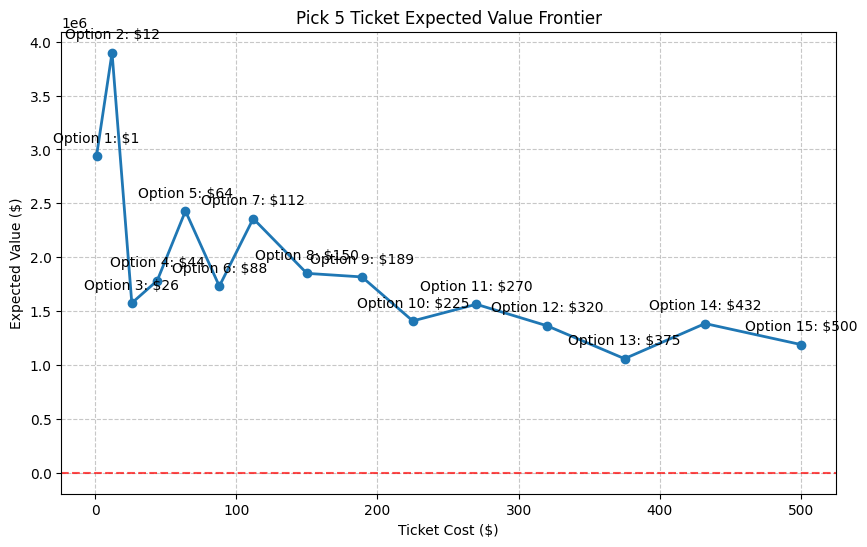

In [42]:
# Find optimal tickets based on expected value
frontier = optimize_pick5_tickets(
    race_probs, 
    morning_lines=morning_lines,
    pool_size=250000,  # $250,000 estimated pool
    takeout_rate=0.22,  # 22% takeout
    max_cost=500,       # Maximum $500 ticket cost
    budget_steps=15
)

# Print top options by expected value
print_pick5_ev_options(frontier, top_n=10)

# Plot the EV frontier
plot = plot_pick5_ev_frontier(frontier)
plot.show()

In [43]:
def optimize_pick5_tickets(race_probs, morning_lines, blend_factor=0.5, pool_size=100000, takeout_rate=0.22, max_cost=None, min_prob=None, budget_steps=20):
    """
    Optimize Pick 5 tickets using a blend of your probability model and morning line odds.
    
    Parameters:
    -----------
    race_probs : dict of dicts
        Dictionary of race probabilities from your model, e.g. {
            'Race 1': {1: 0.4, 2: 0.3, 6: 0.1, ...},
            'Race 2': {3: 0.5, 4: 0.2, ...},
            ...
        }
    morning_lines : dict of dicts
        Dictionary of morning line odds in fractional format, e.g. {
            'Race 1': {1: "2-1", 2: "5-2", 6: "8-1", ...},
            'Race 2': {3: "6-5", 4: "3-1", ...},
            ...
        }
    blend_factor : float
        Weight to assign to your model (0.5 means 50% your model, 50% morning line)
    pool_size : float
        Estimated total amount in the Pick 5 pool
    takeout_rate : float
        Track's takeout percentage (0.22 = 22%)
    max_cost : int, optional
        Maximum number of combinations to consider
    min_prob : float, optional
        Minimum total probability to aim for
    budget_steps : int
        Number of points on the efficiency frontier to calculate
        
    Returns:
    --------
    list of tuples
        Each tuple contains (cost, ev, probability, ticket_selections)
        where ticket_selections is a dict mapping race to list of horse numbers
    """
    # Extract race names
    races = list(race_probs.keys())
    if len(races) != 5:
        raise ValueError("This function requires exactly 5 races")
    
    # Convert morning line odds to implied probabilities
    market_probs = {}
    for race, odds_dict in morning_lines.items():
        market_probs[race] = {}
        for horse, odds_str in odds_dict.items():
            # Parse fractional odds (e.g., "2-1" or "1-2")
            if "-" in odds_str:
                num, denom = odds_str.split("-")
                num, denom = float(num), float(denom)
                # Convert to implied probability
                if num >= denom:  # e.g., 2-1
                    prob = denom / (num + denom)
                else:  # e.g., 1-2
                    prob = denom / (num + denom)
                market_probs[race][horse] = prob
    
    # Create blended probabilities
    blended_probs = {}
    for race in races:
        blended_probs[race] = {}
        # Get all horses from both probability sets
        all_horses = set(race_probs[race].keys()) | set(market_probs[race].keys())
        
        for horse in all_horses:
            # Get probabilities from both sources (default to 0 if missing)
            model_prob = race_probs[race].get(horse, 0)
            market_prob = market_probs[race].get(horse, 0)
            
            # Calculate blended probability
            blended_prob = (blend_factor * model_prob) + ((1 - blend_factor) * market_prob)
            blended_probs[race][horse] = blended_prob
    
    # Normalize blended probabilities to sum to 1 for each race
    for race in races:
        total_prob = sum(blended_probs[race].values())
        if total_prob > 0:  # Avoid division by zero
            for horse in blended_probs[race]:
                blended_probs[race][horse] /= total_prob
    
    # For each race, sort horses by blended probability (descending)
    sorted_horses = {}
    for race, probs in blended_probs.items():
        sorted_horses[race] = sorted(probs.items(), key=itemgetter(1), reverse=True)
    
    # Generate all reasonable combinations of horse counts per race
    max_horses_per_race = [len(sorted_horses[race]) for race in races]
    
    # Start with the most probable horse in each race
    min_selection = [1, 1, 1, 1, 1]
    
    # Generate allocations from minimum to maximum
    all_allocations = []
    for total_horses in range(sum(min_selection), sum(max_horses_per_race) + 1):
        # Only consider allocations where we have at least 1 horse per race
        for allocation in itertools.combinations_with_replacement(range(5), total_horses - 5):
            counts = [1, 1, 1, 1, 1]  # Start with minimum 1 horse per race
            for i in allocation:
                counts[i] += 1
                
            # Skip if any race exceeds its maximum
            if any(counts[i] > max_horses_per_race[i] for i in range(5)):
                continue
                
            all_allocations.append(counts)
    
    # Calculate EV for each allocation
    results = []
    for allocation in all_allocations:
        # Calculate ticket cost (number of combinations)
        cost = np.prod(allocation)
        
        # Skip if cost exceeds max_cost
        if max_cost is not None and cost > max_cost:
            continue
            
        # Calculate total probability and selections
        total_prob = 1.0
        selections = {}
        raw_market_prob = 1.0  # For EV calculation
        
        for i, race in enumerate(races):
            # Get top N horses for this race
            top_horses = sorted_horses[race][:allocation[i]]
            
            # Calculate blended probability for this race
            race_prob = sum(prob for _, prob in top_horses)
            
            # Calculate raw market probability for these horses
            race_market_prob = sum(market_probs[race].get(horse, 0) 
                                 for horse, _ in top_horses)
            
            # Update total probabilities
            total_prob *= race_prob
            raw_market_prob *= race_market_prob
            
            # Store the selected horse numbers
            selections[race] = [horse_num for horse_num, _ in top_horses]
        
        # Skip if probability is below minimum
        if min_prob is not None and total_prob < min_prob:
            continue
        
        # Calculate expected value
        # (We use the contrast between blended probability and raw market probability)
        net_pool = pool_size * (1 - takeout_rate)
        
        # Avoid division by zero
        if raw_market_prob > 0:
            expected_payout = (total_prob / raw_market_prob) * net_pool
            ev = expected_payout - cost
        else:
            ev = -cost  # If market gives zero probability, this is unprofitable
        
        results.append((cost, ev, total_prob, selections))
    
    # Sort by expected value (descending)
    results.sort(key=lambda x: x[1], reverse=True)
    
    # Find the efficient frontier (best EV for each cost level)
    frontier = []
    best_ev_for_cost = {}
    
    for result in results:
        cost, ev, prob, selections = result
        
        # If we haven't seen this cost before, or this EV is better than what we've seen
        if cost not in best_ev_for_cost or ev > best_ev_for_cost[cost]:
            best_ev_for_cost[cost] = ev
            frontier.append(result)
    
    # Sort by cost
    frontier.sort(key=lambda x: x[0])
    
    # If budget_steps is provided, return evenly spaced points along the frontier
    if frontier and budget_steps > 0:
        if budget_steps >= len(frontier):
            return frontier
        
        # Get evenly spaced indices
        indices = np.linspace(0, len(frontier)-1, budget_steps, dtype=int)
        return [frontier[i] for i in indices]
    
    return frontier


def display_blended_probabilities(race_probs, morning_lines, blend_factor=0.5):
    """
    Display the blended probabilities alongside original probabilities.
    
    Parameters:
    -----------
    race_probs : dict of dicts
        Dictionary of race probabilities from your model
    morning_lines : dict of dicts
        Dictionary of morning line odds in fractional format
    blend_factor : float
        Weight to assign to your model
    """
    races = list(race_probs.keys())
    
    # Convert morning line odds to implied probabilities
    market_probs = {}
    for race, odds_dict in morning_lines.items():
        market_probs[race] = {}
        for horse, odds_str in odds_dict.items():
            if "-" in odds_str:
                num, denom = odds_str.split("-")
                num, denom = float(num), float(denom)
                if num >= denom:  # e.g., 2-1
                    prob = denom / (num + denom)
                else:  # e.g., 1-2
                    prob = denom / (num + denom)
                market_probs[race][horse] = prob
    
    # Create blended probabilities
    blended_probs = {}
    for race in races:
        blended_probs[race] = {}
        all_horses = set(race_probs[race].keys()) | set(market_probs[race].keys())
        
        for horse in all_horses:
            model_prob = race_probs[race].get(horse, 0)
            market_prob = market_probs[race].get(horse, 0)
            blended_prob = (blend_factor * model_prob) + ((1 - blend_factor) * market_prob)
            blended_probs[race][horse] = blended_prob
    
    # Normalize blended probabilities
    for race in races:
        total_prob = sum(blended_probs[race].values())
        if total_prob > 0:
            for horse in blended_probs[race]:
                blended_probs[race][horse] /= total_prob
    
    # Display probabilities
    for race in races:
        print(f"\n{race} Probabilities:")
        print(f"{'Horse':<6} {'Model %':<10} {'M.L. %':<10} {'Blended %':<10} {'M.L. Odds':<10}")
        print("-" * 50)
        
        # Get all horses from any set
        all_horses = set(race_probs[race].keys()) | set(market_probs[race].keys())
        
        # Sort by blended probability
        sorted_horses = sorted(all_horses, 
                              key=lambda h: blended_probs[race].get(h, 0), 
                              reverse=True)
        
        for horse in sorted_horses:
            model_prob = race_probs[race].get(horse, 0)
            market_prob = market_probs[race].get(horse, 0)
            blended_prob = blended_probs[race].get(horse, 0)
            odds_str = morning_lines[race].get(horse, "N/A")
            
            print(f"{horse:<6} {model_prob*100:>7.1f}%{'':<2} "
                  f"{market_prob*100:>7.1f}%{'':<2} "
                  f"{blended_prob*100:>7.1f}%{'':<2} "
                  f"{odds_str:<10}")


def print_pick5_ev_options(frontier, top_n=5):
    """
    Print the top N ticket options from the frontier, sorted by EV.
    
    Parameters:
    -----------
    frontier : list of tuples
        List of (cost, ev, probability, selections) tuples
    top_n : int
        Number of options to print
    """
    # Sort by EV (descending)
    sorted_frontier = sorted(frontier, key=lambda x: x[1], reverse=True)
    
    print("\nTop Pick 5 Ticket Options by Expected Value:")
    print("============================================")
    
    for i, (cost, ev, prob, selections) in enumerate(sorted_frontier[:min(top_n, len(sorted_frontier))]):
        print(f"\nOption {i+1}: Cost ${cost:.2f}, Expected Value: ${ev:.2f}")
        print(f"Win Probability: {prob:.4%}")
        print("-" * 60)
        
        for race, horses in selections.items():
            print(f"{race}: {', '.join(map(str, horses))}")
        
        # Calculate ROI
        roi = ev / cost * 100
        print(f"Expected ROI: {roi:.2f}%")


def plot_pick5_ev_frontier(frontier):
    """
    Plot the expected value frontier for Pick 5 tickets.
    
    Parameters:
    -----------
    frontier : list of tuples
        List of (cost, ev, probability, selections) tuples
    """
    costs = [item[0] for item in frontier]
    evs = [item[1] for item in frontier]
    
    plt.figure(figsize=(10, 6))
    plt.plot(costs, evs, 'o-', linewidth=2)
    
    # Add labels for each point
    for i, (cost, ev, _, _) in enumerate(frontier):
        plt.annotate(f"Option {i+1}: ${cost}",
                    (cost, ev),
                    textcoords="offset points",
                    xytext=(0, 10),
                    ha='center')
    
    # Add a horizontal line at EV=0
    plt.axhline(y=0, color='r', linestyle='--', alpha=0.7)
    
    plt.xlabel('Ticket Cost ($)')
    plt.ylabel('Expected Value ($)')
    plt.title('Pick 5 Ticket Expected Value Frontier')
    plt.grid(True, linestyle='--', alpha=0.7)
    
    return plt


Race 1 Probabilities:
Horse  Model %    M.L. %     Blended %  M.L. Odds 
--------------------------------------------------
1         37.8%      28.6%      30.8%   5-2       
2         31.0%      25.0%      26.0%   3-1       
3          6.3%      20.0%      12.2%   4-1       
7         12.2%      11.1%      10.8%   8-1       
6          3.6%      16.7%       9.4%   5-1       
5          3.2%      14.3%       8.1%   6-1       
4          6.0%       0.0%       2.8%   N/A       

Race 2 Probabilities:
Horse  Model %    M.L. %     Blended %  M.L. Odds 
--------------------------------------------------
7         29.7%      22.2%      27.4%   7-2       
5         16.5%      18.2%      18.3%   9-2       
4         19.8%       9.1%      15.2%   10-1      
3          9.7%       7.7%       9.2%   12-1      
10         5.9%       7.7%       7.2%   12-1      
12         3.6%       9.1%       6.7%   10-1      
14         6.1%       4.8%       5.7%   20-1      
8          4.4%       6.2%       5.6

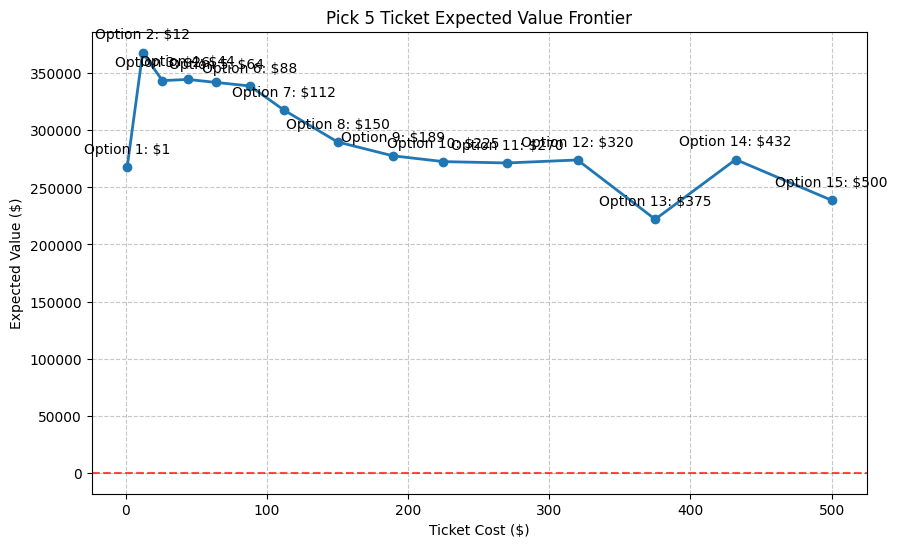

In [44]:
# Display the blended probabilities
blend_factor = 0.5  # 50% your model, 50% morning line
display_blended_probabilities(race_probs, morning_lines, blend_factor)

# Find optimal tickets based on expected value with blended probabilities
frontier = optimize_pick5_tickets(
    race_probs, 
    morning_lines=morning_lines,
    blend_factor=blend_factor,
    pool_size=250000,  # $250,000 estimated pool
    takeout_rate=0.22,  # 22% takeout
    max_cost=500,       # Maximum $500 ticket cost
    budget_steps=15
)

# Print top options by expected value
print_pick5_ev_options(frontier, top_n=10)

# Plot the EV frontier
plot = plot_pick5_ev_frontier(frontier)
plot.show()


Race 1 Probabilities:
Horse  Model %    M.L. %     Blended %  M.L. Odds 
--------------------------------------------------
1         37.8%      28.6%      30.8%   5-2       
2         31.0%      25.0%      26.0%   3-1       
3          6.3%      20.0%      12.2%   4-1       
7         12.2%      11.1%      10.8%   8-1       
6          3.6%      16.7%       9.4%   5-1       
5          3.2%      14.3%       8.1%   6-1       
4          6.0%       0.0%       2.8%   N/A       

Race 2 Probabilities:
Horse  Model %    M.L. %     Blended %  M.L. Odds 
--------------------------------------------------
7         29.7%      22.2%      27.4%   7-2       
5         16.5%      18.2%      18.3%   9-2       
4         19.8%       9.1%      15.2%   10-1      
3          9.7%       7.7%       9.2%   12-1      
10         5.9%       7.7%       7.2%   12-1      
12         3.6%       9.1%       6.7%   10-1      
14         6.1%       4.8%       5.7%   20-1      
8          4.4%       6.2%       5.6

C:\Users\Blake\AppData\Local\Temp\ipykernel_79404\3691016690.py:402: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plot.show()


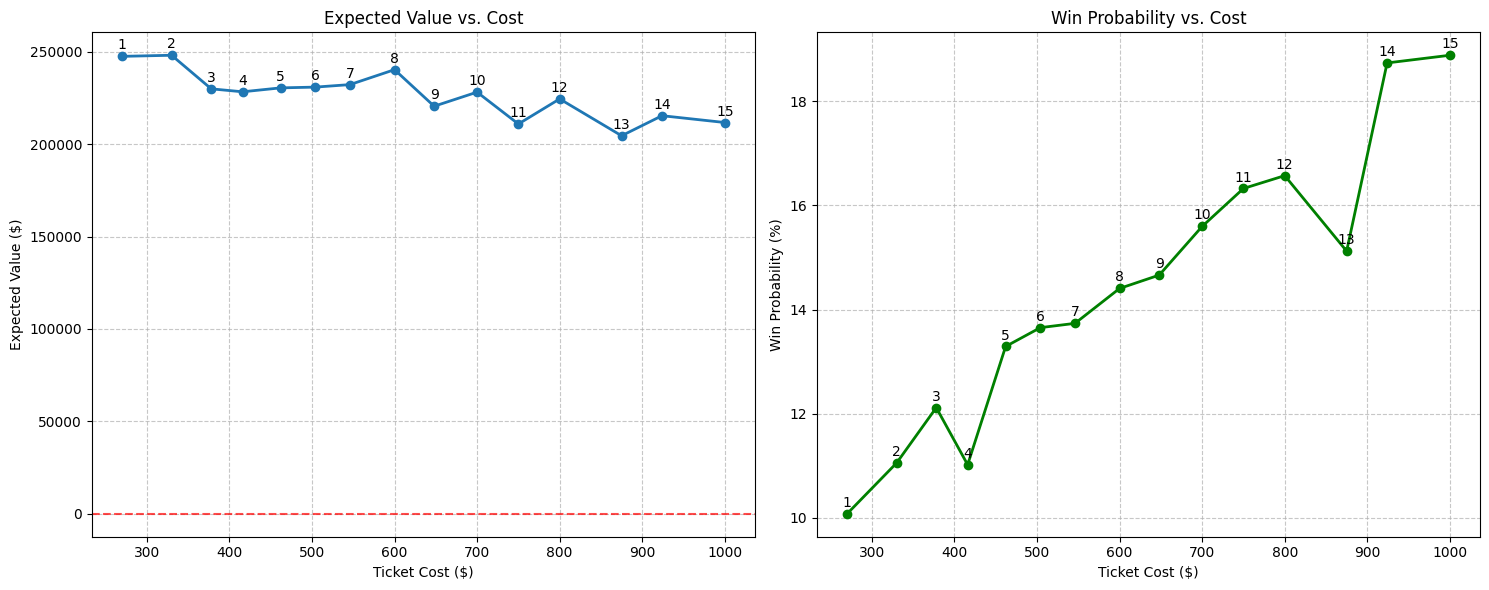

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import itertools
from operator import itemgetter

def optimize_pick5_tickets(race_probs, morning_lines, blend_factor=0.5, pool_size=100000, 
                          takeout_rate=0.22, max_cost=None, min_prob=None, 
                          min_total_prob=None, budget_steps=20):
    """
    Optimize Pick 5 tickets using a blend of your probability model and morning line odds.
    
    Parameters:
    -----------
    race_probs : dict of dicts
        Dictionary of race probabilities from your model, e.g. {
            'Race 1': {1: 0.4, 2: 0.3, 6: 0.1, ...},
            'Race 2': {3: 0.5, 4: 0.2, ...},
            ...
        }
    morning_lines : dict of dicts
        Dictionary of morning line odds in fractional format, e.g. {
            'Race 1': {1: "2-1", 2: "5-2", 6: "8-1", ...},
            'Race 2': {3: "6-5", 4: "3-1", ...},
            ...
        }
    blend_factor : float
        Weight to assign to your model (0.5 means 50% your model, 50% morning line)
    pool_size : float
        Estimated total amount in the Pick 5 pool
    takeout_rate : float
        Track's takeout percentage (0.22 = 22%)
    max_cost : int, optional
        Maximum number of combinations to consider
    min_prob : float, optional
        Minimum probability per race (e.g., 0.7 means we need 70% of each race covered)
    min_total_prob : float, optional
        Minimum total probability across all races (e.g., 0.1 means 10% chance of hitting)
    budget_steps : int
        Number of points on the efficiency frontier to calculate
        
    Returns:
    --------
    list of tuples
        Each tuple contains (cost, ev, probability, ticket_selections)
        where ticket_selections is a dict mapping race to list of horse numbers
    """
    # Extract race names
    races = list(race_probs.keys())
    if len(races) != 5:
        raise ValueError("This function requires exactly 5 races")
    
    # Convert morning line odds to implied probabilities
    market_probs = {}
    for race, odds_dict in morning_lines.items():
        market_probs[race] = {}
        for horse, odds_str in odds_dict.items():
            # Parse fractional odds (e.g., "2-1" or "1-2")
            if "-" in odds_str:
                num, denom = odds_str.split("-")
                num, denom = float(num), float(denom)
                # Convert to implied probability
                if num >= denom:  # e.g., 2-1
                    prob = denom / (num + denom)
                else:  # e.g., 1-2
                    prob = denom / (num + denom)
                market_probs[race][horse] = prob
    
    # Create blended probabilities
    blended_probs = {}
    for race in races:
        blended_probs[race] = {}
        # Get all horses from both probability sets
        all_horses = set(race_probs[race].keys()) | set(market_probs[race].keys())
        
        for horse in all_horses:
            # Get probabilities from both sources (default to 0 if missing)
            model_prob = race_probs[race].get(horse, 0)
            market_prob = market_probs[race].get(horse, 0)
            
            # Calculate blended probability
            blended_prob = (blend_factor * model_prob) + ((1 - blend_factor) * market_prob)
            blended_probs[race][horse] = blended_prob
    
    # Normalize blended probabilities to sum to 1 for each race
    for race in races:
        total_prob = sum(blended_probs[race].values())
        if total_prob > 0:  # Avoid division by zero
            for horse in blended_probs[race]:
                blended_probs[race][horse] /= total_prob
    
    # For each race, sort horses by blended probability (descending)
    sorted_horses = {}
    for race, probs in blended_probs.items():
        sorted_horses[race] = sorted(probs.items(), key=itemgetter(1), reverse=True)
    
    # Generate all reasonable combinations of horse counts per race
    max_horses_per_race = [len(sorted_horses[race]) for race in races]
    
    # Start with the most probable horse in each race
    min_selection = [1, 1, 1, 1, 1]
    
    # If min_prob is provided, adjust minimum selection counts
    if min_prob is not None:
        for i, race in enumerate(races):
            # Calculate how many horses we need to reach min_prob
            cum_prob = 0
            count = 0
            for horse, prob in sorted_horses[race]:
                cum_prob += prob
                count += 1
                if cum_prob >= min_prob:
                    break
            min_selection[i] = max(min_selection[i], count)
    
    # Generate allocations from minimum to maximum
    all_allocations = []
    for total_horses in range(sum(min_selection), sum(max_horses_per_race) + 1):
        allocations_for_total = []
        
        # Start with minimum selections
        base_allocation = min_selection.copy()
        remaining = total_horses - sum(base_allocation)
        
        # Use recursive function to distribute remaining horses
        def distribute_remaining(current, remaining, index=0):
            if index == len(current) - 1:
                # Assign all remaining to the last race (if possible)
                if current[index] + remaining <= max_horses_per_race[index]:
                    new_allocation = current.copy()
                    new_allocation[index] += remaining
                    allocations_for_total.append(new_allocation)
                return
            
            # Try different allocations for this race
            for i in range(remaining + 1):
                if current[index] + i <= max_horses_per_race[index]:
                    new_current = current.copy()
                    new_current[index] += i
                    distribute_remaining(new_current, remaining - i, index + 1)
        
        distribute_remaining(base_allocation, remaining)
        all_allocations.extend(allocations_for_total)
    
    # Calculate EV for each allocation
    results = []
    for allocation in all_allocations:
        # Calculate ticket cost (number of combinations)
        cost = np.prod(allocation)
        
        # Skip if cost exceeds max_cost
        if max_cost is not None and cost > max_cost:
            continue
            
        # Calculate total probability and selections
        total_prob = 1.0
        selections = {}
        raw_market_prob = 1.0  # For EV calculation
        
        for i, race in enumerate(races):
            # Get top N horses for this race
            top_horses = sorted_horses[race][:allocation[i]]
            
            # Calculate blended probability for this race
            race_prob = sum(prob for _, prob in top_horses)
            
            # Calculate raw market probability for these horses
            race_market_prob = sum(market_probs[race].get(horse, 0) 
                                 for horse, _ in top_horses)
            
            # Update total probabilities
            total_prob *= race_prob
            raw_market_prob *= race_market_prob
            
            # Store the selected horse numbers
            selections[race] = [horse_num for horse_num, _ in top_horses]
        
        # Skip if total probability is below minimum
        if min_total_prob is not None and total_prob < min_total_prob:
            continue
        
        # Calculate expected value
        # (We use the contrast between blended probability and raw market probability)
        net_pool = pool_size * (1 - takeout_rate)
        
        # Avoid division by zero
        if raw_market_prob > 0:
            expected_payout = (total_prob / raw_market_prob) * net_pool
            ev = expected_payout - cost
        else:
            ev = -cost  # If market gives zero probability, this is unprofitable
        
        results.append((cost, ev, total_prob, selections))
    
    # Sort by expected value (descending)
    results.sort(key=lambda x: x[1], reverse=True)
    
    # Find the efficient frontier (best EV for each cost level)
    frontier = []
    best_ev_for_cost = {}
    
    for result in results:
        cost, ev, prob, selections = result
        
        # If we haven't seen this cost before, or this EV is better than what we've seen
        if cost not in best_ev_for_cost or ev > best_ev_for_cost[cost]:
            best_ev_for_cost[cost] = ev
            frontier.append(result)
    
    # Sort by cost
    frontier.sort(key=lambda x: x[0])
    
    # If budget_steps is provided, return evenly spaced points along the frontier
    if frontier and budget_steps > 0:
        if budget_steps >= len(frontier):
            return frontier
        
        # Get evenly spaced indices
        indices = np.linspace(0, len(frontier)-1, budget_steps, dtype=int)
        return [frontier[i] for i in indices]
    
    return frontier


def display_blended_probabilities(race_probs, morning_lines, blend_factor=0.5):
    """
    Display the blended probabilities alongside original probabilities.
    
    Parameters:
    -----------
    race_probs : dict of dicts
        Dictionary of race probabilities from your model
    morning_lines : dict of dicts
        Dictionary of morning line odds in fractional format
    blend_factor : float
        Weight to assign to your model
    """
    races = list(race_probs.keys())
    
    # Convert morning line odds to implied probabilities
    market_probs = {}
    for race, odds_dict in morning_lines.items():
        market_probs[race] = {}
        for horse, odds_str in odds_dict.items():
            if "-" in odds_str:
                num, denom = odds_str.split("-")
                num, denom = float(num), float(denom)
                if num >= denom:  # e.g., 2-1
                    prob = denom / (num + denom)
                else:  # e.g., 1-2
                    prob = denom / (num + denom)
                market_probs[race][horse] = prob
    
    # Create blended probabilities
    blended_probs = {}
    for race in races:
        blended_probs[race] = {}
        all_horses = set(race_probs[race].keys()) | set(market_probs[race].keys())
        
        for horse in all_horses:
            model_prob = race_probs[race].get(horse, 0)
            market_prob = market_probs[race].get(horse, 0)
            blended_prob = (blend_factor * model_prob) + ((1 - blend_factor) * market_prob)
            blended_probs[race][horse] = blended_prob
    
    # Normalize blended probabilities
    for race in races:
        total_prob = sum(blended_probs[race].values())
        if total_prob > 0:
            for horse in blended_probs[race]:
                blended_probs[race][horse] /= total_prob
    
    # Display probabilities
    for race in races:
        print(f"\n{race} Probabilities:")
        print(f"{'Horse':<6} {'Model %':<10} {'M.L. %':<10} {'Blended %':<10} {'M.L. Odds':<10}")
        print("-" * 50)
        
        # Get all horses from any set
        all_horses = set(race_probs[race].keys()) | set(market_probs[race].keys())
        
        # Sort by blended probability
        sorted_horses = sorted(all_horses, 
                              key=lambda h: blended_probs[race].get(h, 0), 
                              reverse=True)
        
        for horse in sorted_horses:
            model_prob = race_probs[race].get(horse, 0)
            market_prob = market_probs[race].get(horse, 0)
            blended_prob = blended_probs[race].get(horse, 0)
            odds_str = morning_lines[race].get(horse, "N/A")
            
            print(f"{horse:<6} {model_prob*100:>7.1f}%{'':<2} "
                  f"{market_prob*100:>7.1f}%{'':<2} "
                  f"{blended_prob*100:>7.1f}%{'':<2} "
                  f"{odds_str:<10}")


def print_pick5_ev_options(frontier, top_n=5):
    """
    Print the top N ticket options from the frontier, sorted by EV.
    
    Parameters:
    -----------
    frontier : list of tuples
        List of (cost, ev, probability, selections) tuples
    top_n : int
        Number of options to print
    """
    # Sort by EV (descending)
    sorted_frontier = sorted(frontier, key=lambda x: x[1], reverse=True)
    
    print("\nTop Pick 5 Ticket Options by Expected Value:")
    print("============================================")
    
    for i, (cost, ev, prob, selections) in enumerate(sorted_frontier[:min(top_n, len(sorted_frontier))]):
        print(f"\nOption {i+1}: Cost ${cost:.2f}, Expected Value: ${ev:.2f}")
        print(f"Win Probability: {prob:.4%}")
        print("-" * 60)
        
        for race, horses in selections.items():
            print(f"{race}: {', '.join(map(str, horses))}")
        
        # Calculate ROI
        roi = ev / cost * 100
        print(f"Expected ROI: {roi:.2f}%")


def plot_pick5_ev_frontier(frontier):
    """
    Plot the expected value frontier for Pick 5 tickets.
    
    Parameters:
    -----------
    frontier : list of tuples
        List of (cost, ev, probability, selections) tuples
    """
    costs = [item[0] for item in frontier]
    evs = [item[1] for item in frontier]
    probs = [item[2] for item in frontier]
    
    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # Plot EV vs Cost
    ax1.plot(costs, evs, 'o-', linewidth=2)
    for i, (cost, ev, _, _) in enumerate(frontier):
        ax1.annotate(f"{i+1}",
                    (cost, ev),
                    textcoords="offset points",
                    xytext=(0, 5),
                    ha='center')
    
    ax1.axhline(y=0, color='r', linestyle='--', alpha=0.7)
    ax1.set_xlabel('Ticket Cost ($)')
    ax1.set_ylabel('Expected Value ($)')
    ax1.set_title('Expected Value vs. Cost')
    ax1.grid(True, linestyle='--', alpha=0.7)
    
    # Plot Probability vs Cost
    ax2.plot(costs, [p*100 for p in probs], 'o-', color='green', linewidth=2)
    for i, (cost, _, prob, _) in enumerate(frontier):
        ax2.annotate(f"{i+1}",
                    (cost, prob*100),
                    textcoords="offset points",
                    xytext=(0, 5),
                    ha='center')
    
    ax2.set_xlabel('Ticket Cost ($)')
    ax2.set_ylabel('Win Probability (%)')
    ax2.set_title('Win Probability vs. Cost')
    ax2.grid(True, linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    return fig


# Example usage
if __name__ == "__main__":
    # Example race probabilities (from your t-distribution model)

    # Display the blended probabilities
    blend_factor = 0.5  # 50% your model, 50% morning line
    display_blended_probabilities(race_probs, morning_lines, blend_factor)
    
    # Find optimal tickets with minimum 10% total win probability
    frontier = optimize_pick5_tickets(
        race_probs, 
        morning_lines=morning_lines,
        blend_factor=blend_factor,
        pool_size=250000,  # $250,000 estimated pool
        takeout_rate=0.22,  # 22% takeout
        max_cost=1000,       # Maximum $500 ticket cost
        min_total_prob=0.10,  # Minimum 10% chance of winning
        budget_steps=15
    )
    
    # Print top options by expected value
    print_pick5_ev_options(frontier, top_n=10)
    
    # Plot the EV frontier
    plot = plot_pick5_ev_frontier(frontier)
    plot.show()

In [15]:
import pandas as pd
data = 'C://Users/Blake/Downloads/horseracing - 05_15.csv'
data = pd.read_csv(data)
data['race_3q'] = data.groupby(['Race'])['Composite'].transform(lambda x: x.quantile(0.75))
data['rating'] = data['Composite'] - data['race_3q']
races = list(range(1,6))
race_6_data = data.loc[data['Race']==races[0]].set_index('Number')['rating'].to_dict()
race_7_data = data.loc[data['Race']==races[1]].set_index('Number')['rating'].to_dict()
race_8_data = data.loc[data['Race']==races[2]].set_index('Number')['rating'].to_dict()
race_9_data = data.loc[data['Race']==races[3]].set_index('Number')['rating'].to_dict()
race_10_data = data.loc[data['Race']==races[4]].set_index('Number')['rating'].to_dict()

r6_probs = calculate_win_probabilities_t(race_6_data, degrees_of_freedom=1.3)
r7_probs = calculate_win_probabilities_t(race_7_data, degrees_of_freedom=1.3)
r8_probs = calculate_win_probabilities_t(race_8_data, degrees_of_freedom=1.3)
r9_probs = calculate_win_probabilities_t(race_9_data, degrees_of_freedom=1.3)
r10_probs = calculate_win_probabilities_t(race_10_data, degrees_of_freedom=1.3)

r6_morning = data.loc[data['Race']==races[0]].set_index('Number')['ML'].to_dict()
r7_morning = data.loc[data['Race']==races[1]].set_index('Number')['ML'].to_dict()
r8_morning = data.loc[data['Race']==races[2]].set_index('Number')['ML'].to_dict()
r9_morning = data.loc[data['Race']==races[3]].set_index('Number')['ML'].to_dict()
r10_morning = data.loc[data['Race']==races[4]].set_index('Number')['ML'].to_dict()


In [16]:
r6_morning = {k: str(v)+'-1' for k, v in r6_morning.items()}
r7_morning = {k: str(v)+'-1' for k, v in r7_morning.items()}
r8_morning = {k: str(v)+'-1' for k, v in r8_morning.items()}
r9_morning = {k: str(v)+'-1' for k, v in r9_morning.items()}
r10_morning = {k: str(v)+'-1' for k, v in r10_morning.items()}

In [17]:
display_horse_odds(race_6_data, r6_probs)


Horse Racing Odds Board
#    Mean     Win %      US Odds    Fractional
--------------------------------------------------
2    +14.0       75.8%      +410       1-0.33    
3    +2.0       12.6%      +695       7-1       
5    -6.0       4.7%      +2035      20-1      
1    -9.0       3.8%      +2530      25-1      
4    -24.0       1.8%      +5600      55-1      
6    -31.0       1.4%      +6835      70-1      



In [18]:
display_horse_odds(race_7_data, r7_probs)


Horse Racing Odds Board
#    Mean     Win %      US Odds    Fractional
--------------------------------------------------
4    +7.9       50.1%      +200       1-0.99    
3    +0.4       12.8%      +685       7-1       
6    -0.1       11.9%      +740       7-1       
5    -1.1       10.3%      +875       9-1       
8    -6.1       5.4%      +1765      20-1      
2    -8.1       4.5%      +2140      20-1      
7    -11.1       3.6%      +2655      25-1      
1    -33.1       1.5%      +6665      65-1      



In [19]:
display_horse_odds(race_8_data, r8_probs)


Horse Racing Odds Board
#    Mean     Win %      US Odds    Fractional
--------------------------------------------------
13   +3.0       15.8%      +530       5-1       
12   +2.0       12.9%      +675       7-1       
2    +2.0       12.8%      +680       7-1       
14   +0.0       9.1%      +1000      10-1      
10   +0.0       9.1%      +1000      10-1      
16   -1.5       7.3%      +1270      15-1      
5    -2.0       6.8%      +1365      15-1      
15   -4.5       5.3%      +1805      20-1      
9    -7.0       4.0%      +2370      25-1      
7    -8.0       3.8%      +2540      25-1      
3    -9.0       3.4%      +2835      30-1      
6    -14.0       2.6%      +3785      40-1      
4    -16.0       2.4%      +4005      40-1      
8    -19.0       2.0%      +4835      50-1      
11   -26.0       1.5%      +6560      65-1      
1    -38.0       1.1%      +9135      90-1      



In [20]:
display_horse_odds(race_9_data, r9_probs)


Horse Racing Odds Board
#    Mean     Win %      US Odds    Fractional
--------------------------------------------------
3    +3.2       35.7%      +180       2-1       
7    +1.2       24.3%      +310       3-1       
1    -1.2       14.7%      +580       6-1       
5    -1.8       13.4%      +645       6-1       
6    -10.2       4.9%      +1955      20-1      
2    -10.8       4.5%      +2145      20-1      
4    -20.8       2.5%      +3830      40-1      



In [21]:
display_horse_odds(race_10_data, r10_probs)


Horse Racing Odds Board
#    Mean     Win %      US Odds    Fractional
--------------------------------------------------
4    +11.5       59.6%      +245       1-0.68    
5    +1.5       10.9%      +815       8-1       
7    +0.5       9.3%      +970       10-1      
10   -1.5       7.1%      +1315      15-1      
8    -6.5       4.3%      +2225      20-1      
3    -12.5       2.9%      +3385      35-1      
2    -17.5       2.2%      +4445      45-1      
6    -26.5       1.6%      +6200      60-1      
9    -31.5       1.4%      +7180      70-1      
1    -56.5       0.8%      +13095     130-1     



In [22]:
race_probs = {
    'Race 1': r6_probs,
    'Race 2': r7_probs,
    'Race 3': r8_probs,
    'Race 4': r9_probs,
    'Race 5': r10_probs
}

In [23]:
morning_lines = {
    'Race 1': r6_morning,
    'Race 2': r7_morning,
    'Race 3': r8_morning,
    'Race 4': r9_morning,
    'Race 5': r10_morning
}

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import itertools
from operator import itemgetter

def optimize_pick_tickets(race_probs, morning_lines, bet_type=5, blend_factor=0.5, pool_size=100000, 
                         takeout_rate=0.22, max_cost=None, min_prob=None, 
                         min_total_prob=None, budget_steps=20):
    """
    Optimize Pick 4 or Pick 5 tickets using a blend of your probability model and morning line odds.
    
    Parameters:
    -----------
    race_probs : dict of dicts
        Dictionary of race probabilities from your model, e.g. {
            'Race 1': {1: 0.4, 2: 0.3, 6: 0.1, ...},
            'Race 2': {3: 0.5, 4: 0.2, ...},
            ...
        }
    morning_lines : dict of dicts
        Dictionary of morning line odds in fractional format, e.g. {
            'Race 1': {1: "2-1", 2: "5-2", 6: "8-1", ...},
            'Race 2': {3: "6-5", 4: "3-1", ...},
            ...
        }
    bet_type : int
        4 for Pick 4, 5 for Pick 5
    blend_factor : float
        Weight to assign to your model (0.5 means 50% your model, 50% morning line)
    pool_size : float
        Estimated total amount in the Pick pool
    takeout_rate : float
        Track's takeout percentage (0.22 = 22%)
    max_cost : int, optional
        Maximum number of combinations to consider
    min_prob : float, optional
        Minimum probability per race (e.g., 0.7 means we need 70% of each race covered)
    min_total_prob : float, optional
        Minimum total probability across all races (e.g., 0.1 means 10% chance of hitting)
    budget_steps : int
        Number of points on the efficiency frontier to calculate
        
    Returns:
    --------
    list of tuples
        Each tuple contains (cost, ev, probability, ticket_selections)
        where ticket_selections is a dict mapping race to list of horse numbers
    """
    # Extract race names
    races = list(race_probs.keys())
    if len(races) != bet_type:
        raise ValueError(f"This function requires exactly {bet_type} races for a Pick {bet_type}")
    
    # Convert morning line odds to implied probabilities
    market_probs = {}
    for race, odds_dict in morning_lines.items():
        market_probs[race] = {}
        for horse, odds_str in odds_dict.items():
            # Parse fractional odds (e.g., "2-1" or "1-2")
            if "-" in odds_str:
                num, denom = odds_str.split("-")
                num, denom = float(num), float(denom)
                # Convert to implied probability
                if num >= denom:  # e.g., 2-1
                    prob = denom / (num + denom)
                else:  # e.g., 1-2
                    prob = denom / (num + denom)
                market_probs[race][horse] = prob
    
    # Create blended probabilities
    blended_probs = {}
    for race in races:
        blended_probs[race] = {}
        # Get all horses from both probability sets
        all_horses = set(race_probs[race].keys()) | set(market_probs[race].keys())
        
        for horse in all_horses:
            # Get probabilities from both sources (default to 0 if missing)
            model_prob = race_probs[race].get(horse, 0)
            market_prob = market_probs[race].get(horse, 0)
            
            # Calculate blended probability
            blended_prob = (blend_factor * model_prob) + ((1 - blend_factor) * market_prob)
            blended_probs[race][horse] = blended_prob
    
    # Normalize blended probabilities to sum to 1 for each race
    for race in races:
        total_prob = sum(blended_probs[race].values())
        if total_prob > 0:  # Avoid division by zero
            for horse in blended_probs[race]:
                blended_probs[race][horse] /= total_prob
    
    # For each race, sort horses by blended probability (descending)
    sorted_horses = {}
    for race, probs in blended_probs.items():
        sorted_horses[race] = sorted(probs.items(), key=itemgetter(1), reverse=True)
    
    # Generate all reasonable combinations of horse counts per race
    max_horses_per_race = [len(sorted_horses[race]) for race in races]
    
    # Start with the most probable horse in each race
    min_selection = [1] * bet_type
    
    # If min_prob is provided, adjust minimum selection counts
    if min_prob is not None:
        for i, race in enumerate(races):
            # Calculate how many horses we need to reach min_prob
            cum_prob = 0
            count = 0
            for horse, prob in sorted_horses[race]:
                cum_prob += prob
                count += 1
                if cum_prob >= min_prob:
                    break
            min_selection[i] = max(min_selection[i], count)
    
    # Generate allocations from minimum to maximum
    all_allocations = []
    for total_horses in range(sum(min_selection), sum(max_horses_per_race) + 1):
        allocations_for_total = []
        
        # Start with minimum selections
        base_allocation = min_selection.copy()
        remaining = total_horses - sum(base_allocation)
        
        # Use recursive function to distribute remaining horses
        def distribute_remaining(current, remaining, index=0):
            if index == len(current) - 1:
                # Assign all remaining to the last race (if possible)
                if current[index] + remaining <= max_horses_per_race[index]:
                    new_allocation = current.copy()
                    new_allocation[index] += remaining
                    allocations_for_total.append(new_allocation)
                return
            
            # Try different allocations for this race
            for i in range(remaining + 1):
                if current[index] + i <= max_horses_per_race[index]:
                    new_current = current.copy()
                    new_current[index] += i
                    distribute_remaining(new_current, remaining - i, index + 1)
        
        distribute_remaining(base_allocation, remaining)
        all_allocations.extend(allocations_for_total)
    
    # Calculate EV for each allocation
    results = []
    for allocation in all_allocations:
        # Calculate ticket cost (number of combinations)
        cost = np.prod(allocation)
        
        # Skip if cost exceeds max_cost
        if max_cost is not None and cost > max_cost:
            continue
            
        # Calculate total probability and selections
        total_prob = 1.0
        selections = {}
        raw_market_prob = 1.0  # For EV calculation
        
        for i, race in enumerate(races):
            # Get top N horses for this race
            top_horses = sorted_horses[race][:allocation[i]]
            
            # Calculate blended probability for this race
            race_prob = sum(prob for _, prob in top_horses)
            
            # Calculate raw market probability for these horses
            race_market_prob = sum(market_probs[race].get(horse, 0) 
                                 for horse, _ in top_horses)
            
            # Update total probabilities
            total_prob *= race_prob
            raw_market_prob *= race_market_prob
            
            # Store the selected horse numbers
            selections[race] = [horse_num for horse_num, _ in top_horses]
        
        # Skip if total probability is below minimum
        if min_total_prob is not None and total_prob < min_total_prob:
            continue
        
        # Calculate expected value
        net_pool = pool_size * (1 - takeout_rate)
        
        # Avoid division by zero
        if raw_market_prob > 0:
            expected_payout = (total_prob / raw_market_prob) * net_pool
            ev = expected_payout - cost
        else:
            ev = -cost  # If market gives zero probability, this is unprofitable
        
        results.append((cost, ev, total_prob, selections))
    
    # Sort by expected value (descending)
    results.sort(key=lambda x: x[1], reverse=True)
    
    # Find the efficient frontier (best EV for each cost level)
    frontier = []
    best_ev_for_cost = {}
    
    for result in results:
        cost, ev, prob, selections = result
        
        # If we haven't seen this cost before, or this EV is better than what we've seen
        if cost not in best_ev_for_cost or ev > best_ev_for_cost[cost]:
            best_ev_for_cost[cost] = ev
            frontier.append(result)
    
    # Sort by cost
    frontier.sort(key=lambda x: x[0])
    
    # If budget_steps is provided, return evenly spaced points along the frontier
    if frontier and budget_steps > 0:
        if budget_steps >= len(frontier):
            return frontier
        
        # Get evenly spaced indices
        indices = np.linspace(0, len(frontier)-1, budget_steps, dtype=int)
        return [frontier[i] for i in indices]
    
    return frontier


def display_blended_probabilities(race_probs, morning_lines, blend_factor=0.5):
    """
    Display the blended probabilities alongside original probabilities.
    
    Parameters:
    -----------
    race_probs : dict of dicts
        Dictionary of race probabilities from your model
    morning_lines : dict of dicts
        Dictionary of morning line odds in fractional format
    blend_factor : float
        Weight to assign to your model
    """
    races = list(race_probs.keys())
    
    # Convert morning line odds to implied probabilities
    market_probs = {}
    for race, odds_dict in morning_lines.items():
        market_probs[race] = {}
        for horse, odds_str in odds_dict.items():
            if "-" in odds_str:
                num, denom = odds_str.split("-")
                num, denom = float(num), float(denom)
                if num >= denom:  # e.g., 2-1
                    prob = denom / (num + denom)
                else:  # e.g., 1-2
                    prob = denom / (num + denom)
                market_probs[race][horse] = prob
    
    # Create blended probabilities
    blended_probs = {}
    for race in races:
        blended_probs[race] = {}
        all_horses = set(race_probs[race].keys()) | set(market_probs[race].keys())
        
        for horse in all_horses:
            model_prob = race_probs[race].get(horse, 0)
            market_prob = market_probs[race].get(horse, 0)
            blended_prob = (blend_factor * model_prob) + ((1 - blend_factor) * market_prob)
            blended_probs[race][horse] = blended_prob
    
    # Normalize blended probabilities
    for race in races:
        total_prob = sum(blended_probs[race].values())
        if total_prob > 0:
            for horse in blended_probs[race]:
                blended_probs[race][horse] /= total_prob
    
    # Display probabilities
    for race in races:
        print(f"\n{race} Probabilities:")
        print(f"{'Horse':<6} {'Model %':<10} {'M.L. %':<10} {'Blended %':<10} {'M.L. Odds':<10}")
        print("-" * 50)
        
        # Get all horses from any set
        all_horses = set(race_probs[race].keys()) | set(market_probs[race].keys())
        
        # Sort by blended probability
        sorted_horses = sorted(all_horses, 
                              key=lambda h: blended_probs[race].get(h, 0), 
                              reverse=True)
        
        for horse in sorted_horses:
            model_prob = race_probs[race].get(horse, 0)
            market_prob = market_probs[race].get(horse, 0)
            blended_prob = blended_probs[race].get(horse, 0)
            odds_str = morning_lines[race].get(horse, "N/A")
            
            print(f"{horse:<6} {model_prob*100:>7.1f}%{'':<2} "
                  f"{market_prob*100:>7.1f}%{'':<2} "
                  f"{blended_prob*100:>7.1f}%{'':<2} "
                  f"{odds_str:<10}")


def print_pick_ev_options(frontier, bet_type=5, top_n=5):
    """
    Print the top N ticket options from the frontier, sorted by EV.
    
    Parameters:
    -----------
    frontier : list of tuples
        List of (cost, ev, probability, selections) tuples
    bet_type : int
        4 for Pick 4, 5 for Pick 5
    top_n : int
        Number of options to print
    """
    # Sort by EV (descending)
    sorted_frontier = sorted(frontier, key=lambda x: x[1], reverse=True)
    
    print(f"\nTop Pick {bet_type} Ticket Options by Expected Value:")
    print("=" * 45)
    
    for i, (cost, ev, prob, selections) in enumerate(sorted_frontier[:min(top_n, len(sorted_frontier))]):
        print(f"\nOption {i+1}: Cost ${cost:.2f}, Expected Value: ${ev:.2f}")
        print(f"Win Probability: {prob:.4%}")
        print("-" * 60)
        
        for race, horses in selections.items():
            print(f"{race}: {', '.join(map(str, horses))}")
        
        # Calculate ROI
        roi = ev / cost * 100
        print(f"Expected ROI: {roi:.2f}%")


def plot_pick_ev_frontier(frontier, bet_type=5):
    """
    Plot the expected value frontier for Pick 4/5 tickets.
    
    Parameters:
    -----------
    frontier : list of tuples
        List of (cost, ev, probability, selections) tuples
    bet_type : int
        4 for Pick 4, 5 for Pick 5
    """
    costs = [item[0] for item in frontier]
    evs = [item[1] for item in frontier]
    probs = [item[2] for item in frontier]
    
    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # Plot EV vs Cost
    ax1.plot(costs, evs, 'o-', linewidth=2)
    for i, (cost, ev, _, _) in enumerate(frontier):
        ax1.annotate(f"{i+1}",
                    (cost, ev),
                    textcoords="offset points",
                    xytext=(0, 5),
                    ha='center')
    
    ax1.axhline(y=0, color='r', linestyle='--', alpha=0.7)
    ax1.set_xlabel('Ticket Cost ($)')
    ax1.set_ylabel('Expected Value ($)')
    ax1.set_title(f'Pick {bet_type}: Expected Value vs. Cost')
    ax1.grid(True, linestyle='--', alpha=0.7)
    
    # Plot Probability vs Cost
    ax2.plot(costs, [p*100 for p in probs], 'o-', color='green', linewidth=2)
    for i, (cost, _, prob, _) in enumerate(frontier):
        ax2.annotate(f"{i+1}",
                    (cost, prob*100),
                    textcoords="offset points",
                    xytext=(0, 5),
                    ha='center')
    
    ax2.set_xlabel('Ticket Cost ($)')
    ax2.set_ylabel('Win Probability (%)')
    ax2.set_title(f'Pick {bet_type}: Win Probability vs. Cost')
    ax2.grid(True, linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    return fig



Race 1 Probabilities:
Horse  Model %    M.L. %     Blended %  M.L. Odds 
--------------------------------------------------
2         75.8%      28.6%      54.5%   2.5-1     
3         12.6%      25.0%      15.3%   3.0-1     
5          4.7%      33.3%      13.2%   2.0-1     
1          3.8%      22.2%       9.2%   3.5-1     
4          1.8%      14.3%       5.5%   6.0-1     
6          1.4%       4.8%       2.3%   20.0-1    

Race 2 Probabilities:
Horse  Model %    M.L. %     Blended %  M.L. Odds 
--------------------------------------------------
4         50.1%      28.6%      39.3%   2.5-1     
6         11.9%      25.0%      15.0%   3.0-1     
3         12.8%      18.2%      13.4%   4.5-1     
5         10.3%      11.1%       9.7%   8.0-1     
7          3.6%      16.7%       7.4%   5.0-1     
8          5.4%      11.1%       6.7%   8.0-1     
2          4.5%      11.1%       6.2%   8.0-1     
1          1.5%       4.8%       2.4%   20.0-1    

Race 3 Probabilities:
Horse  Model 

C:\Users\Blake\AppData\Local\Temp\ipykernel_14248\3040026923.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plot.show()


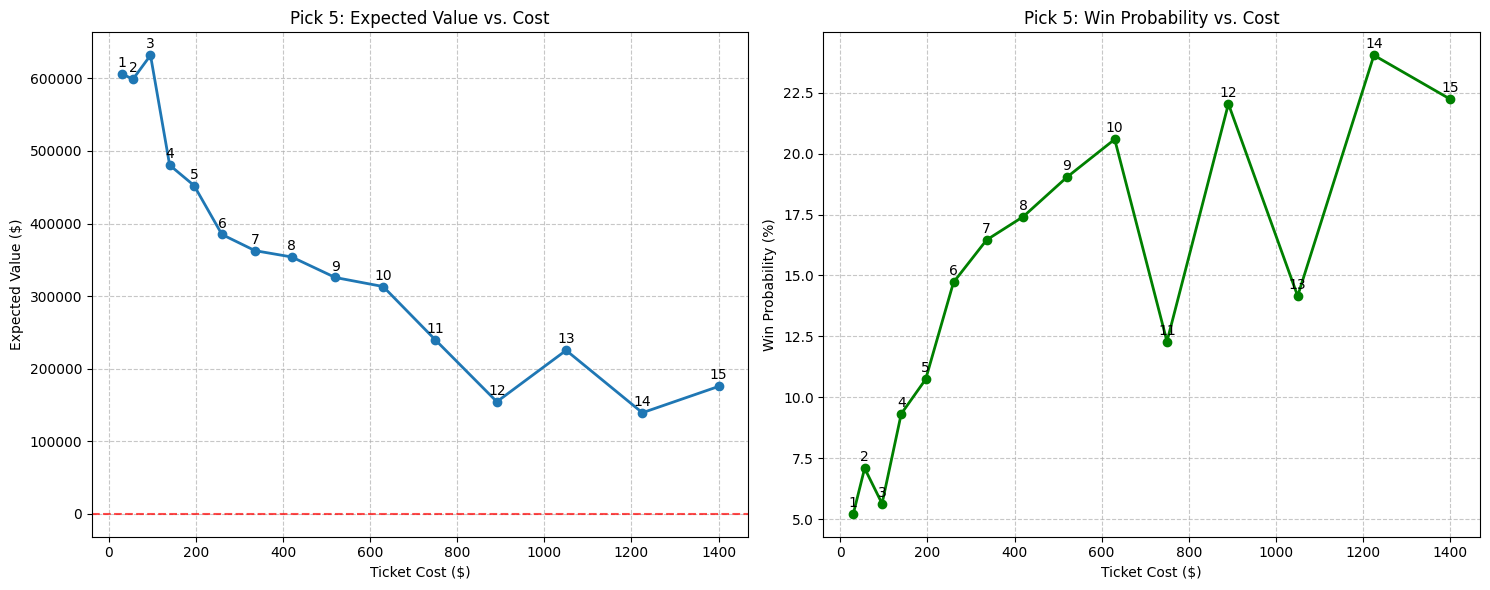

In [25]:


# Display the blended probabilities
blend_factor = 0.66
display_blended_probabilities(race_probs, morning_lines, blend_factor)

# Find optimal tickets with minimum 10% total win probability
frontier = optimize_pick_tickets(
    race_probs, 
    morning_lines=morning_lines,
    bet_type=5,  # Pick 4
    blend_factor=blend_factor,
    pool_size=300000,  # $150,000 estimated pool
    takeout_rate=0.22,  # 22% takeout
    max_cost=1400,       # Maximum $300 ticket cost
    
    
    
    
    min_total_prob=0.05,  # Minimum 10% chance of winning
    
    budget_steps=15
)

# Print top options by expected value
print_pick_ev_options(frontier, bet_type=5, top_n=25)

# Plot the EV frontier
plot = plot_pick_ev_frontier(frontier, bet_type=5)
plot.show()



